# 14. Inference-view and cropping sensitivity

## 1. Introduction

RQ3 also examines how automatic inference views affect Bacterial Spot predictions at standard 224 × 224 model input size. We compare fixed center-crop and five-crop inference using the same four frozen checkpoints as Notebook 09. These interventions jointly change object scale, field of view and image coverage; they do not isolate lesion resolution.

ViT Mixed recognizes 3/18 Bacterial Spot images on Field Dev with the standard transform and 5/18 with a 0.50 source crop. On external v1, five-crop inference recognizes 6/9 and gives 38/62 correct overall (macro-F1 0.5840). These are exploratory comparisons after the external outcomes were inspected, with no further checkpoint or inference-policy selection.

This study extends the external evaluation in Notebook 11 and the human-reviewed Healthy crop analysis in Notebook 13. Per-image predictions and view geometry support the quantitative comparisons and qualitative examples.

## 2. Experimental setup

Field Dev contains 92 PlantDoc images, including 18 Bacterial Spot images; it was used for checkpoint selection. External v1 contains 62 images: 16 self-collected Healthy images and 46 online disease images, including 9 Bacterial Spot images. Acquisition source and class are confounded. Neither set is a new independent confirmation of this exploration.

Class order is Healthy, Early Blight, Late Blight, Bacterial Spot, Septoria Leaf Spot. Macro-F1 averages all five labels with undefined values set to zero. Cached inference is loaded by default; the explicit command below creates a **new** output directory if a rerun is needed. Checkpoints and source images are local and excluded from Git.

In [1]:
from pathlib import Path
import json
import sys
import warnings
# Optional progress widgets are unnecessary for cached analysis.
warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src').is_dir() and (p / 'notebooks').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.evaluate_resolution_sensitivity import (
    MODEL_NAMES, CLASS_NAMES, REGIMES, FIVE_BOXES, sha256_file, summarize,
    prepare_views, load_model, load_external,
)
EVIDENCE = ROOT / 'outputs/research_integration/20261126_reconciliation'
RUN = EVIDENCE / 'inference'
FIGURES = EVIDENCE / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
SHORT = dict(zip(REGIMES, ['Standard', 'Center 0.70', 'Center 0.50', 'Five-crop']))
COLORS = ['#4477AA', '#EE7733', '#228833', '#AA3377']

Reproduction from the repository root, if new inference is required:

```bash
.venv/bin/python -m src.evaluate_resolution_sensitivity --output outputs/resolution_sensitivity/NEW_RUN
```

The command refuses existing output directories and reads the recorded PlantDoc Arrow cache without downloading or modifying data. The recorded checkpoints, local source images and cache are required. This notebook uses the saved local predictions by default; repeating inference is unnecessary to reproduce its tables and figures.

In [2]:
protocol = json.loads((RUN / 'protocol.json').read_text())
for name, expected in protocol['output_sha256'].items():
    assert sha256_file(RUN / name) == expected, name
predictions = pd.concat([pd.read_csv(RUN / f'predictions_{key}.csv') for key in MODEL_NAMES], ignore_index=True)
assert not predictions.duplicated(['protocol', 'partition', 'model_key', 'regime', 'image_id']).any()
assert np.allclose(predictions[[f'probability_label_{i}' for i in range(5)]].sum(axis=1), 1, atol=1e-6)
summary = summarize(predictions)
assert len(summary) == 52
selected = summary[(summary.protocol.eq('canonical_exif') & summary.partition.eq('external_field_v1')) |
                   (summary.protocol.eq('upstream_raw') & summary.partition.eq('verified_field_dev'))].copy()
display(pd.DataFrame([
    {'Partition': 'Field Dev', 'Images': 92, 'Bacterial Spot': 18, 'Role': 'Development / exploratory'},
    {'Partition': 'External v1', 'Images': 62, 'Bacterial Spot': 9, 'Role': 'Exploratory reuse; mixed acquisition sources'},
]))

,Partition,Images,Bacterial Spot,Role
0,Field Dev,92,18,Development / exploratory
1,External v1,62,9,Exploratory reuse; mixed acquisition sources


### Checkpoints and preprocessing

All strategies use the same fixed weights in evaluation mode, float32 softmax and no gradients. SHA-256 checks link the checkpoints to Notebook 11; checkpoint metadata records architecture, label order, adaptation settings and source checkpoint linkage.

External images follow Notebook 11: EXIF orientation is applied before RGB conversion. PlantDoc follows the established RGB loader. The tables and figures use these same dataset-specific decoding conventions throughout. Model-specific standard transforms and the spatial changes introduced by each strategy are described below.

In [3]:
provenance_table = pd.DataFrame([
    {'Model': MODEL_NAMES[key], 'Architecture': record['architecture'],
     'Checkpoint': record['checkpoint'], 'SHA-256': record['checkpoint_sha256']}
    for key, record in protocol['models'].items()
])
for record in protocol['models'].values():
    assert sha256_file(ROOT / record['checkpoint']) == record['checkpoint_sha256']
display(provenance_table)
display(pd.DataFrame([protocol['environment']]))

,Model,Architecture,Checkpoint,SHA-256
0,ResNet18 · Lab baseline,resnet18,models/resnet18_lab_best.pt,65d53766258f26cb505cce4c319c3f783cb0f3c6ef4608...
1,ViT-Small · Lab baseline,vit_small_patch16_224.augreg_in1k,models/vit_small_lab_best.pt,42c26a8aa70311d9504d55dda422f20e2ea5f0a5878f59...
2,ResNet18 · Geometric + Mixed,resnet18,models/resnet18_geometric_mixed_best.pt,20bf844b4bc931f4b891b1ffc6c1c59cf178d1b7cf9466...
3,ViT-Small · Mixed,vit_small_patch16_224.augreg_in1k,models/vit_small_mixed_best.pt,4a064e328502737dee736bc88b76952f21d0d4163ac6ad...


,python,torch,torchvision,timm,Pillow,numpy,device,threads
0,3.13.7,2.15.0,0.29.2,1.0.26,13.0.0,2.5.4,cpu,4


## 3. Inference strategies

| Strategy | Operation before model normalization | Model input |
| --- | --- | --- |
| Standard | Architecture-specific resize and center crop | 224 × 224 |
| Center 0.70 | Center source box: rounded 0.70 × width and height; then standard transform | 224 × 224 |
| Center 0.50 | Center source box: rounded 0.50 × width and height; then standard transform | 224 × 224 |
| Five-crop | Bicubic resize to a **square 448 × 448 canvas**, four corners plus center | Five 224 × 224 inputs |

ResNet18 standard inference resizes the shorter side to 256 using bilinear interpolation and center-crops 224. ViT-Small uses its saved AugReg transform (bicubic, crop fraction 0.90, shorter side 248, center crop 224, mean/std 0.5). The source center boxes preserve aspect ratio before these transforms. The square-448 method stretches non-square images and bypasses the standard resize/center crop, retaining model-specific normalization.

Five-crop coordinates are right/bottom exclusive. Probabilities are averaged **after** each view's softmax, followed by one image-level argmax. Weights are unchanged. Center fractions describe the source box, not a lesion annotation or guaranteed lesion magnification.

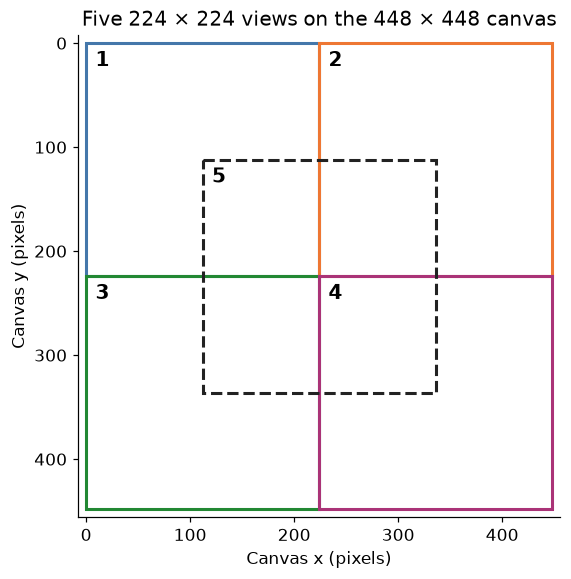

,Left,Top,Right,Bottom
1,0,0,224,224
2,224,0,448,224
3,0,224,224,448
4,224,224,448,448
5,112,112,336,336


In [4]:
fig, ax = plt.subplots(figsize=(7, 5.4))
for i, box in enumerate(FIVE_BOXES):
    left, top, right, bottom = box
    ax.add_patch(Rectangle((left, top), right-left, bottom-top, fill=False,
                           lw=2, linestyle='--' if i == 4 else '-',
                           edgecolor=COLORS[i % 4] if i < 4 else '#222222'))
    ax.text(left+9, top+22, str(i+1), fontsize=13, weight='bold')
ax.set(xlim=(-8, 456), ylim=(456, -8), aspect='equal', xlabel='Canvas x (pixels)',
       ylabel='Canvas y (pixels)', title='Five 224 × 224 views on the 448 × 448 canvas')
fig.tight_layout()
fig.savefig(FIGURES / 'five_crop_geometry.png', dpi=160)
plt.show()
display(pd.DataFrame(FIVE_BOXES, columns=['Left', 'Top', 'Right', 'Bottom'], index=range(1, 6)))

## 4. Bacterial Spot results

The chart uses image-level predictions after aggregation, with class denominators fixed within each panel. A change of one correct image equals 5.6 percentage points on Field Dev and 11.1 points on external v1.

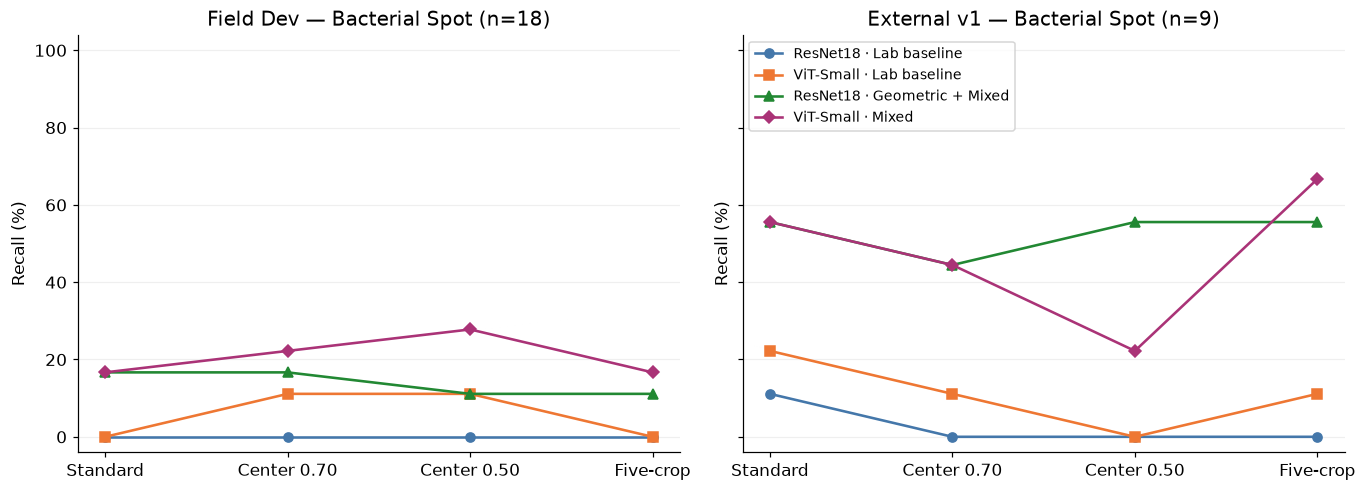

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6), sharey=True)
for ax, partition, title in zip(axes, ['verified_field_dev', 'external_field_v1'],
                                ['Field Dev — Bacterial Spot (n=18)', 'External v1 — Bacterial Spot (n=9)']):
    for (key, name), color, marker in zip(MODEL_NAMES.items(), COLORS, ['o', 's', '^', 'D']):
        frame = selected[selected.partition.eq(partition) & selected.model_key.eq(key)].set_index('regime').loc[list(REGIMES)]
        ax.plot(range(4), frame.bacterial_spot_recall*100, label=name, color=color, marker=marker, lw=1.7)
    ax.set(xticks=range(4), xticklabels=list(SHORT.values()), ylim=(-4, 104), title=title, ylabel='Recall (%)')
    ax.grid(axis='y', alpha=.2)
axes[1].legend(fontsize=9, loc='upper left')
fig.tight_layout()
fig.savefig(FIGURES / 'bacterial_spot_recall.png', dpi=160)
plt.show()

In [6]:
mixed = selected[selected.model_key.isin(['resnet_mixed', 'vit_mixed'])].copy()
mixed['Model'] = mixed.model_key.map(MODEL_NAMES)
mixed['Strategy'] = mixed.regime.map(SHORT)
mixed['Bacterial Spot correct / n'] = mixed.bacterial_spot_correct.astype(str) + '/' + mixed.bacterial_spot_n.astype(str)
display(mixed[['partition', 'Model', 'Strategy', 'Bacterial Spot correct / n', 'accuracy', 'macro_f1']]
        .style.format({'accuracy': '{:.4f}', 'macro_f1': '{:.4f}'}))

,partition,Model,Strategy,Bacterial Spot correct / n,accuracy,macro_f1
30,verified_field_dev,ResNet18 · Geometric + Mixed,Standard,3/18,0.4674,0.4459
31,verified_field_dev,ResNet18 · Geometric + Mixed,Center 0.70,3/18,0.4239,0.3694
32,verified_field_dev,ResNet18 · Geometric + Mixed,Center 0.50,2/18,0.4022,0.3603
33,verified_field_dev,ResNet18 · Geometric + Mixed,Five-crop,2/18,0.4130,0.4121
34,external_field_v1,ResNet18 · Geometric + Mixed,Standard,5/9,0.5323,0.4882
35,external_field_v1,ResNet18 · Geometric + Mixed,Center 0.70,4/9,0.4677,0.4206
36,external_field_v1,ResNet18 · Geometric + Mixed,Center 0.50,5/9,0.4677,0.4092
37,external_field_v1,ResNet18 · Geometric + Mixed,Five-crop,5/9,0.5161,0.4441
43,verified_field_dev,ViT-Small · Mixed,Standard,3/18,0.4022,0.3872
44,verified_field_dev,ViT-Small · Mixed,Center 0.70,4/18,0.4457,0.4201


ViT Mixed increases Field Dev Bacterial Spot recognition from 3/18 to 4/18 and 5/18 under the two center crops. Its five-crop result remains 3/18. ResNet Mixed changes from 3/18 to 3/18, 2/18 and 2/18. These small class-level changes do not establish a consistent resolution benefit.

On external v1, ViT Mixed changes from 5/9 to 6/9 with five-crop aggregation; the 0.50 crop falls to 2/9. ResNet Mixed stays at 5/9 with five-crop inference. The source fractions are fixed, without lesion locations or manual crop selection.

## 5. Model comparison and class trade-offs

Overall macro-F1 shows whether a Bacterial Spot improvement accompanies a broader improvement. The full five-class prediction vectors are retained; results are not selected using the external comparison.

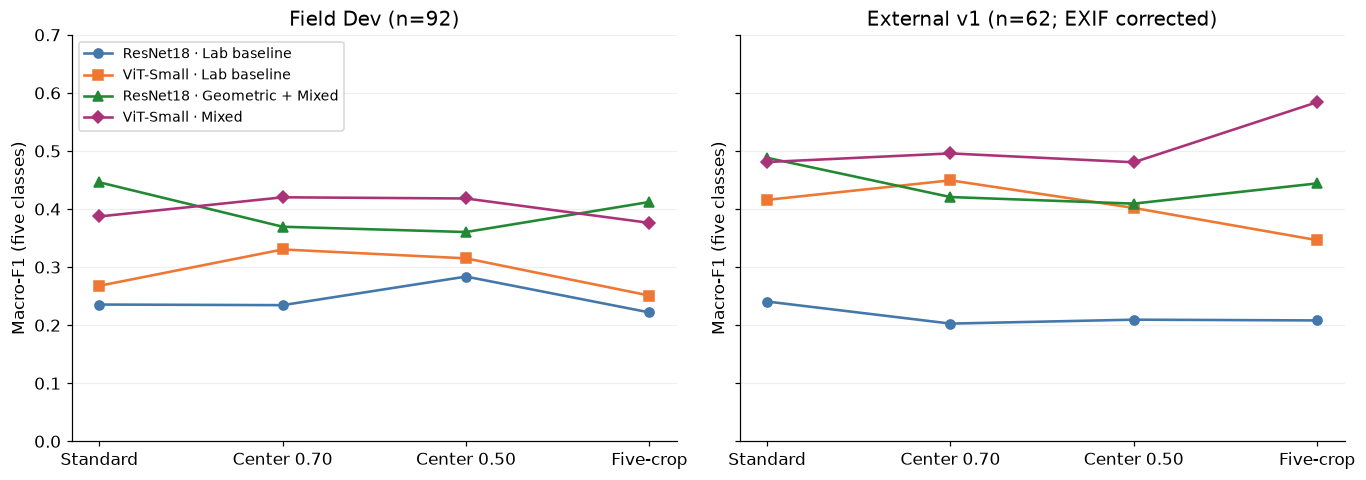

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.5), sharey=True)
for ax, partition, title in zip(axes, ['verified_field_dev', 'external_field_v1'],
                                ['Field Dev (n=92)', 'External v1 (n=62; EXIF corrected)']):
    for (key, name), color, marker in zip(MODEL_NAMES.items(), COLORS, ['o', 's', '^', 'D']):
        frame = selected[selected.partition.eq(partition) & selected.model_key.eq(key)].set_index('regime').loc[list(REGIMES)]
        ax.plot(range(4), frame.macro_f1, label=name, color=color, marker=marker, lw=1.7)
    ax.set(xticks=range(4), xticklabels=list(SHORT.values()), ylim=(0, .7), title=title, ylabel='Macro-F1 (five classes)')
    ax.grid(axis='y', alpha=.2)
axes[0].legend(fontsize=9, loc='upper left')
fig.tight_layout()
fig.savefig(FIGURES / 'macro_f1_by_strategy.png', dpi=160)
plt.show()

In [8]:
external = predictions[predictions.protocol.eq('canonical_exif')].copy()
class_rows = []
for key in ['resnet_mixed', 'vit_mixed']:
    for label, name in enumerate(CLASS_NAMES):
        record = {'Model': MODEL_NAMES[key], 'Class': name}
        for regime in [REGIMES[0], REGIMES[3]]:
            frame = external[external.model_key.eq(key) & external.regime.eq(regime) & external.label_id.eq(label)]
            record[SHORT[regime]] = f'{frame.correct.sum()}/{len(frame)}'
        class_rows.append(record)
display(pd.DataFrame(class_rows))

,Model,Class,Standard,Five-crop
0,ResNet18 · Geometric + Mixed,Healthy,12/16,14/16
1,ResNet18 · Geometric + Mixed,Early Blight,1/13,0/13
2,ResNet18 · Geometric + Mixed,Late Blight,8/11,9/11
3,ResNet18 · Geometric + Mixed,Bacterial Spot,5/9,5/9
4,ResNet18 · Geometric + Mixed,Septoria Leaf Spot,7/13,4/13
5,ViT-Small · Mixed,Healthy,13/16,15/16
6,ViT-Small · Mixed,Early Blight,2/13,5/13
7,ViT-Small · Mixed,Late Blight,8/11,8/11
8,ViT-Small · Mixed,Bacterial Spot,5/9,6/9
9,ViT-Small · Mixed,Septoria Leaf Spot,4/13,4/13


The external ViT Mixed five-crop result is 38/62 correct (0.6129), macro-F1 0.5840, compared with 32/62 (0.5161), macro-F1 0.4808 under standard inference. Both results use the same EXIF-oriented source images and checkpoint. The five-crop comparison is exploratory because external outcomes had already been inspected.

On Field Dev, ResNet Mixed macro-F1 falls from 0.4459 to 0.3603 under the 0.50 center crop. Removing peripheral context or leaves is a plausible explanation requiring image review; these aggregate scores do not establish that mechanism.

## 6. Examples and failure analysis

Examples are selected deterministically from external Bacterial Spot images: five-crop gains, losses, and remaining errors for ViT Mixed. Ground truth is retained from the manifest. The local gallery shows actual normalized-and-restored model inputs; the final column includes all five views. This permits review of coverage and visibility without assuming which pixels caused a prediction.

Photographs remain in ignored local outputs and are linked rather than embedded in the saved notebook.

In [9]:
vit = external[external.model_key.eq('vit_mixed') & external.label_id.eq(3)]
pivot = vit.pivot(index='image_id', columns='regime', values='predicted_label_id').sort_index()
gains = pivot.index[pivot[REGIMES[0]].ne(3) & pivot[REGIMES[3]].eq(3)].tolist()
losses = pivot.index[pivot[REGIMES[0]].eq(3) & pivot[REGIMES[3]].ne(3)].tolist()
remaining = pivot.index[pivot[REGIMES[3]].ne(3)].tolist()
example_ids = list(dict.fromkeys(gains[:2] + losses[:1] + remaining[:2]))[:4]
example_table = pivot.loc[example_ids, [REGIMES[0], REGIMES[2], REGIMES[3]]].copy()
example_table = example_table.rename(columns=SHORT).map(lambda value: CLASS_NAMES[int(value)])
display(example_table)
reference = json.loads((ROOT / 'outputs/external_evaluation/tomato_field_eval_v1/20261125_163347_4ca8183f/evaluation_protocol.json').read_text())
model, standard, normalize, _ = load_model(ROOT, 'vit_mixed', reference)
images, metadata = load_external(ROOT, True)
fig, axes = plt.subplots(len(example_ids), 4, figsize=(12, 3.05*len(example_ids)), squeeze=False)
for row_index, image_id in enumerate(example_ids):
    image = images[metadata.index[metadata.image_id.eq(image_id)][0]]
    for col, regime in enumerate(REGIMES):
        tensors, geometry = prepare_views(image, regime, standard, normalize)
        rgb = [(t.permute(1, 2, 0).numpy()*.5+.5).clip(0, 1) for t in tensors]
        if len(rgb) == 5:
            canvas = np.ones((448, 672, 3))
            for j, view in enumerate(rgb):
                y, x = (j//3)*224, (j%3)*224
                canvas[y:y+224, x:x+224] = view
        else:
            canvas = rgb[0]
        axes[row_index, col].imshow(canvas)
        axes[row_index, col].axis('off')
        prediction = vit[vit.image_id.eq(image_id) & vit.regime.eq(regime)].iloc[0]
        axes[row_index, col].set_title(f'{image_id} · {SHORT[regime]}\n{CLASS_NAMES[int(prediction.predicted_label_id)]} ({prediction.confidence:.2f})', fontsize=10)
fig.suptitle('Local-only model inputs — manifest Bacterial Spot examples', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .97])
fig.savefig(FIGURES / 'qualitative_local_only.png', dpi=145)
plt.close(fig)
del model
display(Markdown('[Open local model-input gallery](../outputs/research_integration/20261126_reconciliation/figures/qualitative_local_only.png)'))

regime,Standard,Center 0.50,Five-crop
image_id,,,
WEB_0001,Septoria Leaf Spot,Bacterial Spot,Bacterial Spot
WEB_0006,Septoria Leaf Spot,Septoria Leaf Spot,Septoria Leaf Spot
WEB_0037,Septoria Leaf Spot,Septoria Leaf Spot,Septoria Leaf Spot


[Open local model-input gallery](../outputs/research_integration/20261126_reconciliation/figures/qualitative_local_only.png)

WEB_0001 changes from Septoria Leaf Spot under standard inference to the manifest Bacterial Spot label under center 0.50 and five-crop inference. WEB_0006 and WEB_0037 remain classified as Septoria Leaf Spot under all four strategies. The linked inputs show framing and coverage changes, but neither a prediction change nor a visible spot proves that a lesion was the decisive feature. There are no lesion masks, object-size annotations or blinded localization judgments in this study.

## 7. Discussion and conclusion

The evidence supports **sensitivity to cropping and coverage**, with model- and dataset-specific effects. Fixed center crops can remove useful content while enlarging other content. Five-crop inference adds views and changes scale, aspect ratio and aggregation. Every forward pass remains 224 × 224, so this experiment cannot establish an advantage of a true 448 × 448 model input or quantify preserved lesion detail.

Notebook 13 answers a related but different question: human-reviewed Healthy leaf crops versus their parent photographs. Its 23 parents, 49 crops and 21 recorded scene groups must not be treated as independent plants or pooled with this five-class study. Here the crops are automatic spatial interventions and the units remain parent images.

Important limitations include small class denominators, reused external outcomes, source/class confounding, development-set checkpoint selection and one training seed. The four model configurations differ in pretraining and training recipes; field-only and mixed-domain adaptation also have unequal field-image exposure. The observed differences do not isolate architecture or a single training factor.

Fixed cropping does not consistently improve Bacterial Spot recognition: the 0.50 crop increases ViT Mixed Field Dev recall to 5/18 but reduces its external recall to 2/9. Five-crop external inference reaches 6/9, while Field Dev remains at 3/18. These results motivate further study of framing and coverage rather than selection of a final inference policy. Prospective confirmation would require a locked policy, new photographs with recorded groups, and lesion or object annotations to separate resolution from coverage effects.